In [4]:
import cv2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Librerias importadas correctamente")

Librerias importadas correctamente


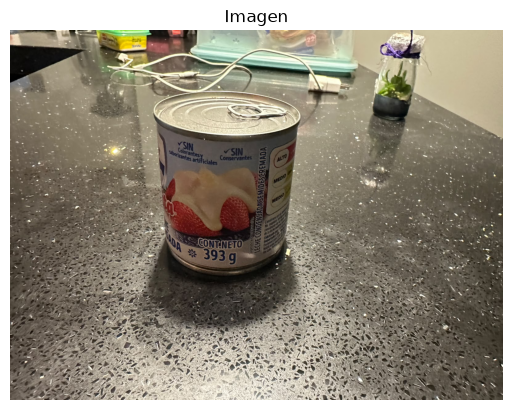

In [5]:
ruta_imagen = "images/lechcon34.jpeg"
imagen = cv2.imread(ruta_imagen)
if imagen is None:
    raise FileNotFoundError("No se encontro la imagen")

imagen_rgb= cv2.cvtColor(imagen,cv2.COLOR_BGR2RGB)
plt.imshow(imagen_rgb)
plt.title("Imagen")
plt.axis("off")
plt.show()


In [6]:
def histograma(eje, gris, titulo, color="#42A5F5"):
    eje.hist(gris.ravel(), bins=256, range=(0, 256), color=color)
    eje.set_title(titulo)
    eje.set_xlim(0, 255)
    eje.set_yticks([])
    
def mostrar(imagenes, titulos, cmap=None, ancho=4):
    fig, ejes = plt.subplots(1, len(imagenes), figsize=(ancho * len(imagenes), ancho))
    for eje, im, t in zip(np.atleast_1d(ejes), imagenes, titulos):
        if im.ndim == 2:
            fijo = im.dtype == np.uint8
            eje.imshow(im, cmap=cmap or "gray", vmin=0 if fijo else None, vmax=255 if fijo else None)
        else:
            eje.imshow(im)
        eje.set_title(t)
        eje.axis("off")
    plt.tight_layout()
    plt.show()


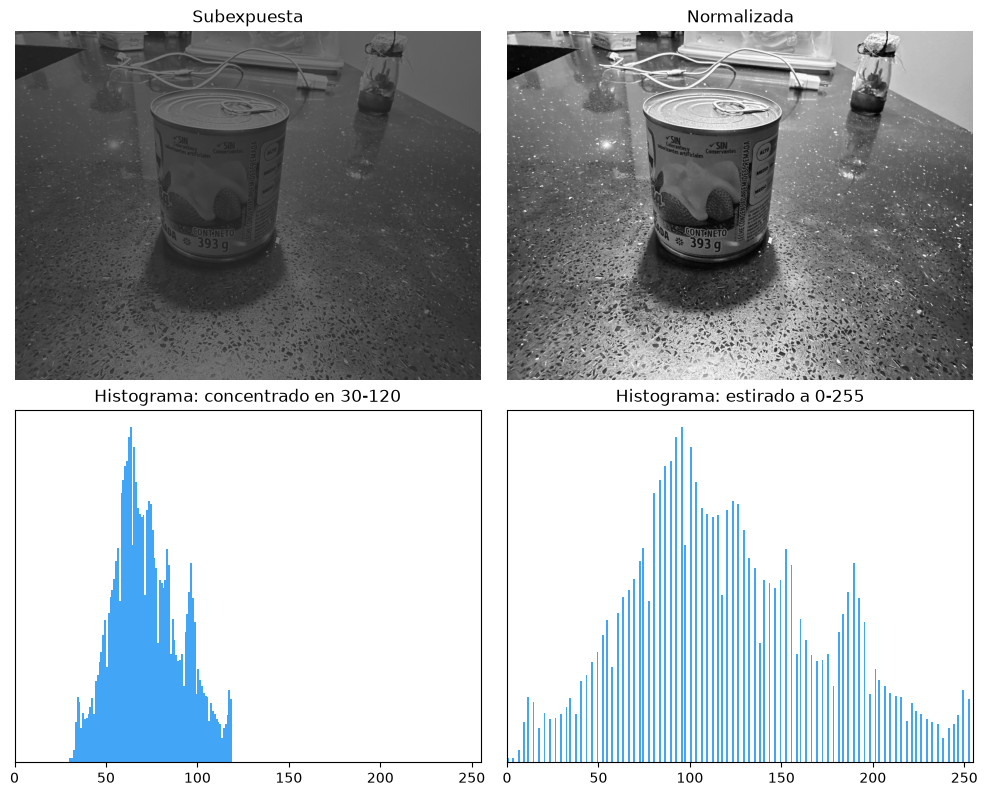

In [7]:
np.random.seed(42)
gris = cv2.cvtColor(imagen_rgb,cv2.COLOR_RGB2GRAY)
subexpuesta = (gris * 0.35 + 30).astype(np.uint8)

minimo, maximo = int(subexpuesta.min()), int(subexpuesta.max())
manual = ((subexpuesta.astype(float) - minimo) / (maximo - minimo) * 255).astype(np.uint8)
opencv = cv2.normalize(subexpuesta, None, 0, 255, cv2.NORM_MINMAX)

fig, ejes = plt.subplots(2, 2, figsize=(10, 8))
ejes[0, 0].imshow(subexpuesta, cmap="gray", vmin=0, vmax=255)
ejes[0, 0].set_title("Subexpuesta")
ejes[0, 1].imshow(opencv, cmap="gray", vmin=0, vmax=255)
ejes[0, 1].set_title("Normalizada")
histograma(ejes[1, 0], subexpuesta, "Histograma: concentrado en 30-120")
histograma(ejes[1, 1], opencv, "Histograma: estirado a 0-255")
for e in ejes[0]:
    e.axis("off")
plt.tight_layout()
plt.show()


Diferencia máxima ecualización manual vs cv2.equalizeHist: 0


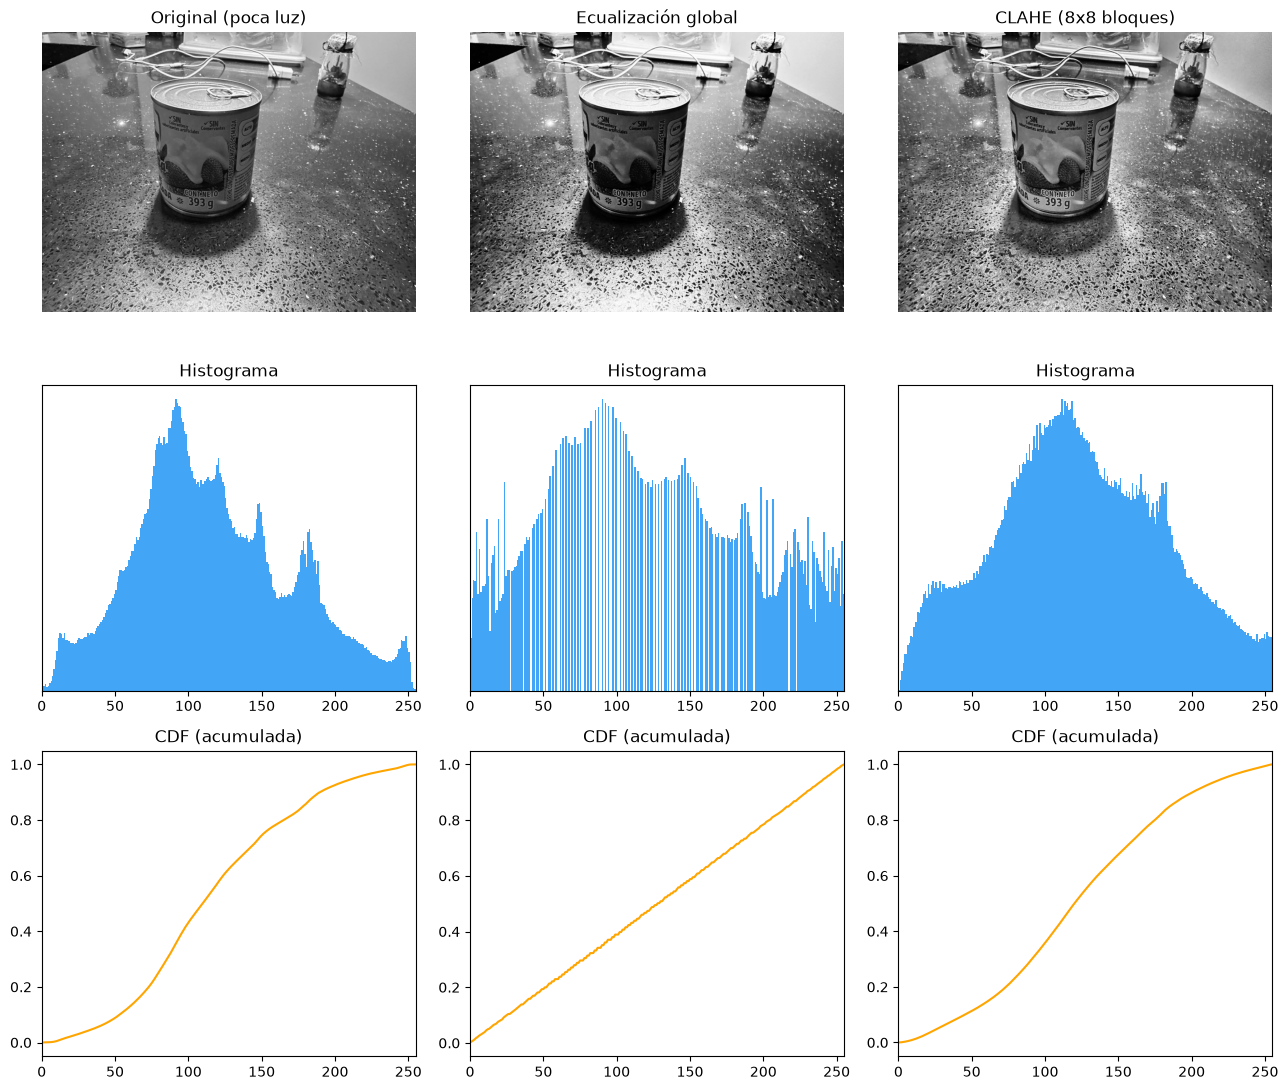

Original    media =  117.0   desviación estándar (contraste) =  52.7
Ecualizada  media =  128.2   desviación estándar (contraste) =  73.5
CLAHE       media =  123.3   desviación estándar (contraste) =  57.1


In [8]:
gris_oscura = cv2.cvtColor(imagen, cv2.COLOR_RGB2GRAY)

hist = np.bincount(gris_oscura.ravel(), minlength=256)
cdf = hist.cumsum()
cdf_min = cdf[cdf > 0][0]
tabla = np.round((cdf - cdf_min) / (gris_oscura.size - cdf_min) * 255).clip(0, 255).astype(np.uint8)
ecualizada_manual = tabla[gris_oscura]  # cada nivel v se reemplaza por tabla[v]
ecualizada = cv2.equalizeHist(gris_oscura)
print("Diferencia máxima ecualización manual vs cv2.equalizeHist:",
    np.abs(ecualizada_manual.astype(int) - ecualizada.astype(int)).max())

# CLAHE: ecualización por bloques con límite de contraste (evita amplificar ruido)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(gris_oscura)

fig, ejes = plt.subplots(3, 3, figsize=(13, 11))
for c, (img, nombre) in enumerate([(gris_oscura, "Original (poca luz)"),
                                (ecualizada, "Ecualización global"), (clahe, "CLAHE (8x8 bloques)")]):
    ejes[0, c].imshow(img, cmap="gray", vmin=0, vmax=255)
    ejes[0, c].set_title(nombre)
    ejes[0, c].axis("off")
    histograma(ejes[1, c], img, "Histograma")
    cdf_img = np.bincount(img.ravel(), minlength=256).cumsum()
    ejes[2, c].plot(cdf_img / cdf_img[-1], color="orange")
    ejes[2, c].set_title("CDF (acumulada)")
    ejes[2, c].set_xlim(0, 255)
plt.tight_layout()
plt.show()
for nombre, img in [("Original", gris_oscura), ("Ecualizada", ecualizada), ("CLAHE", clahe)]:
    print(f"{nombre:<11} media = {img.mean():6.1f}   desviación estándar (contraste) = {img.std():5.1f}")

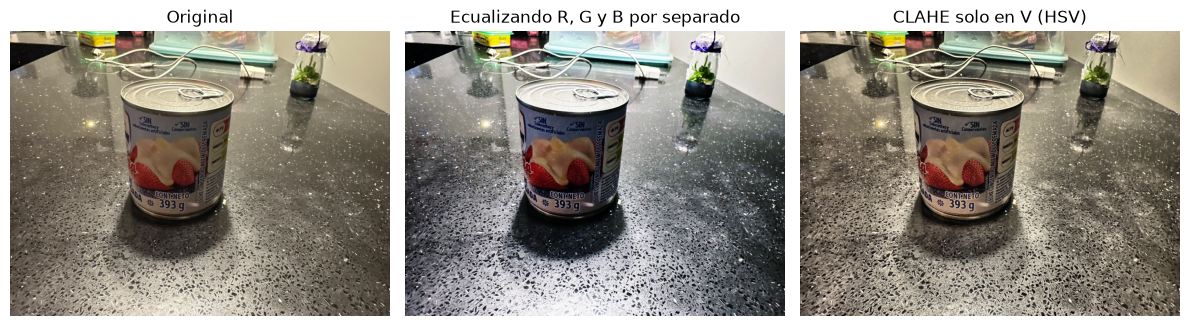

In [9]:
hsv = cv2.cvtColor(imagen_rgb, cv2.COLOR_RGB2HSV)
hsv_v = hsv.copy()
hsv_v[..., 2] = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(hsv[..., 2])
color_v = cv2.cvtColor(hsv_v, cv2.COLOR_HSV2RGB)
por_canal = np.dstack([cv2.equalizeHist(imagen_rgb[..., i]) for i in range(3)])
mostrar([imagen_rgb, por_canal, color_v],
        ["Original", "Ecualizando R, G y B por separado", "CLAHE solo en V (HSV)"])

<div id="Vecindarios" style="color:#37475a; border-bottom: 7px solid orange; width: 100%; margin-bottom: 15px; padding-bottom: 2px"><h2>2. Operaciones sobre grupos de puntos: convolución y filtros</h2> </div>


<div style="color:#106ba3"><h3>2.1 Convolución paso a paso</h3> </div>

La convolución desliza un **kernel** $K$ sobre la imagen $I$ y en cada posición calcula una suma ponderada de la vecindad:

$$(I * K)(x, y) = \sum_i \sum_j I(x+i,\, y+j)\, K(i, j)$$

> **Nota:** La fórmula anterior (sin invertir el kernel) se llama formalmente **correlación**, y es exactamente la operación que implementan `cv2.filter2D` y las capas `Conv2D` de redes neuronales convolucionales (CNNs). Para kernels simétricos (como el de media o el Gaussiano), convolución y correlación dan resultados idénticos.

Primero implementamos la función manual con doble bucle sobre una matriz sintética de 6×6 con un salto brusco de intensidad para analizar el comportamiento numérico.


In [10]:
def convolucion(imagen, kernel):
    k = kernel.shape[0] // 2
    # Relleno (padding) replicando los bordes para mantener el tamaño original
    con_borde = np.pad(imagen.astype(float), k, mode="edge")
    salida = np.zeros(imagen.shape, dtype=float)
    for y in range(imagen.shape[0]):
        for x in range(imagen.shape[1]):
            vecindad = con_borde[y:y + 2 * k + 1, x:x + 2 * k + 1]
            salida[y, x] = (vecindad * kernel).sum()
    return salida


pequena = np.array([[10, 10, 10, 200, 200, 200],
                    [10, 10, 10, 200, 200, 200],
                    [10, 10, 10, 200, 200, 200],
                    [10, 10, 10, 200, 200, 200],
                    [10, 10, 10, 200, 200, 200],
                    [10, 10, 10, 200, 200, 200]], dtype=np.uint8)
media_3x3 = np.ones((3, 3)) / 9
sobel_x = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=float)

print("Imagen sintética 6x6 con borde vertical:\n", pequena)
print("\nConvolución con kernel de media 3x3:\n", convolucion(pequena, media_3x3).round(0))
print("\nConvolución con Sobel x (detecta cambios horizontales de intensidad):\n", convolucion(pequena, sobel_x))


Imagen sintética 6x6 con borde vertical:
 [[ 10  10  10 200 200 200]
 [ 10  10  10 200 200 200]
 [ 10  10  10 200 200 200]
 [ 10  10  10 200 200 200]
 [ 10  10  10 200 200 200]
 [ 10  10  10 200 200 200]]

Convolución con kernel de media 3x3:
 [[ 10.  10.  73. 137. 200. 200.]
 [ 10.  10.  73. 137. 200. 200.]
 [ 10.  10.  73. 137. 200. 200.]
 [ 10.  10.  73. 137. 200. 200.]
 [ 10.  10.  73. 137. 200. 200.]
 [ 10.  10.  73. 137. 200. 200.]]

Convolución con Sobel x (detecta cambios horizontales de intensidad):
 [[  0.   0. 760. 760.   0.   0.]
 [  0.   0. 760. 760.   0.   0.]
 [  0.   0. 760. 760.   0.   0.]
 [  0.   0. 760. 760.   0.   0.]
 [  0.   0. 760. 760.   0.   0.]
 [  0.   0. 760. 760.   0.   0.]]


> **Observación.** Con el kernel de **media** el salto brusco $10 \rightarrow 200$ se convierte en una transición suave ($10, 73, 137, 200$), lo cual corresponde al efecto de **suavizado**. Por el contrario, con **Sobel x** el resultado es $0$ en las regiones homogéneas y genera un valor alto ($760$) en la posición exacta del cambio de intensidad, permitiendo **detectar bordes**.


Diferencia máxima entre nuestra convolución manual y cv2.filter2D: 0.0


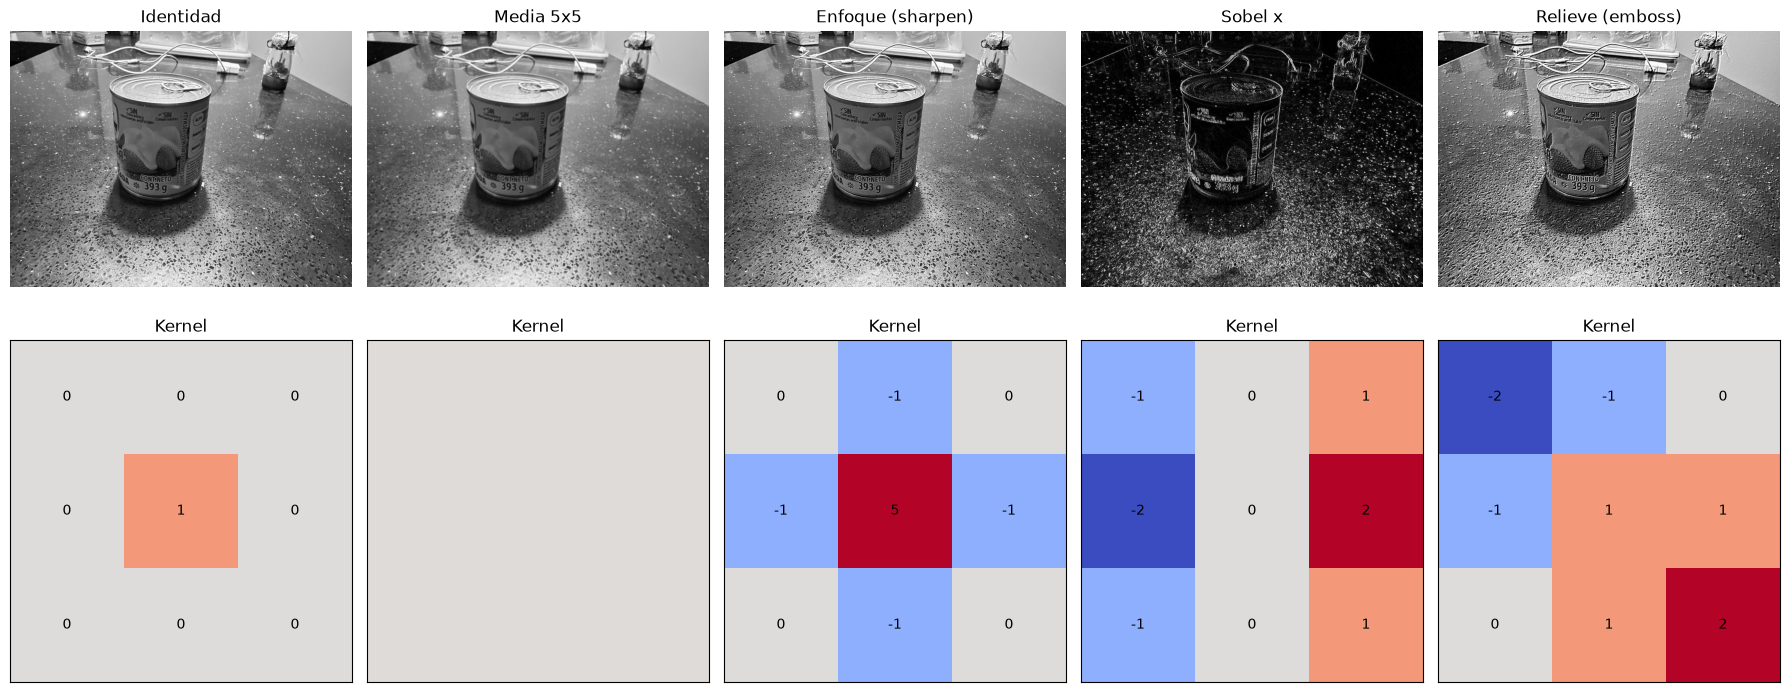

In [11]:
# Aplicación sobre la fotografía de nuestro producto
recorte = gris[550:650, 750:850]
manual = convolucion(recorte, sobel_x)
opencv = cv2.filter2D(recorte.astype(float), -1, sobel_x, borderType=cv2.BORDER_REPLICATE)
print("Diferencia máxima entre nuestra convolución manual y cv2.filter2D:", np.abs(manual - opencv).max())

# Banco de kernels clásicos aplicados a la fotografía del producto
kernels = {
    "Identidad": np.array([[0, 0, 0], [0, 1, 0], [0, 0, 0]], dtype=float),
    "Media 5x5": np.ones((5, 5)) / 25,
    "Enfoque (sharpen)": np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], dtype=float),
    "Sobel x": sobel_x,
    "Relieve (emboss)": np.array([[-2, -1, 0], [-1, 1, 1], [0, 1, 2]], dtype=float),
}

fig, ejes = plt.subplots(2, len(kernels), figsize=(18, 7.5))
for c, (nombre, k) in enumerate(kernels.items()):
    salida = cv2.filter2D(gris.astype(float), -1, k)
    if nombre == "Sobel x":
        salida = np.abs(salida)
    ejes[0, c].imshow(np.clip(salida, 0, 255), cmap="gray", vmin=0, vmax=255)
    ejes[0, c].set_title(nombre)
    ejes[0, c].axis("off")
    
    ejes[1, c].imshow(k, cmap="coolwarm", vmin=-2, vmax=2)
    if k.shape[0] == 3:
        for (i, j), v in np.ndenumerate(k):
            ejes[1, c].text(j, i, f"{v:g}", ha="center", va="center")
    ejes[1, c].set_title("Kernel")
    ejes[1, c].set_xticks([])
    ejes[1, c].set_yticks([])
plt.tight_layout()
plt.show()


> **Observación.** La implementación manual de la convolución coincide con una diferencia de 0.0 respecto a `cv2.filter2D`, demostrando el principio matemático exacto. Al cambiar los coeficientes del kernel obtenemos efectos diversos sobre la imagen del producto: copiar exactamente la imagen (identidad), desenfocarla (media), resaltar letras y detalles finos del envase (enfoque), extraer bordes verticales (Sobel x) o simular relieve 3D (*emboss*).


<div style="color:#106ba3"><h3>2.2 a 2.5 Filtros de media, mediana y Gaussiano para reducir ruido</h3> </div>

| Filtro | Cómo calcula el nuevo píxel | Tipo |
|---|---|---|
| **Media** | Promedio de la vecindad (todos los píxeles pesan igual). | Lineal (convolución). |
| **Mediana** | Mediana estadística de la vecindad (ordena y selecciona el valor central). | No lineal (estadístico de orden). |
| **Gaussiano** | Promedio ponderado donde los vecinos cercanos pesan más según $G(x,y)=\frac{1}{2\pi\sigma^2}e^{-\frac{x^2+y^2}{2\sigma^2}}$. | Lineal (convolución). |

Analizamos primero el efecto del parámetro de dispersión $\sigma$ en el kernel Gaussiano y posteriormente comparamos cuantitativamente la recuperación de la imagen limpia frente a ruidos sintéticos mediante la métrica **PSNR** (*Peak Signal-to-Noise Ratio*, en dB): **a mayor valor de PSNR, mayor fidelidad con la imagen original**.


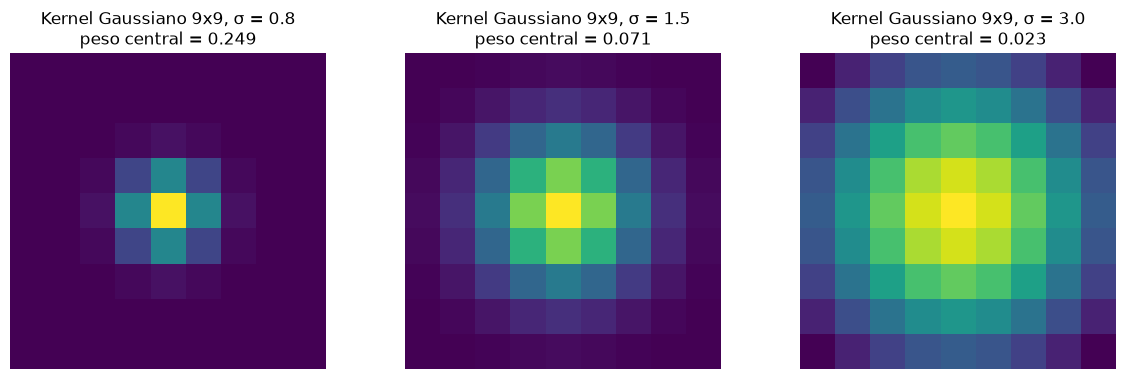

In [12]:
fig, ejes = plt.subplots(1, 3, figsize=(12, 3.8))
for eje, sigma in zip(ejes, [0.8, 1.5, 3.0]):
    g = cv2.getGaussianKernel(9, sigma)
    kernel_2d = g @ g.T
    eje.imshow(kernel_2d, cmap="viridis")
    eje.set_title(f"Kernel Gaussiano 9x9, σ = {sigma}\npeso central = {kernel_2d[4, 4]:.3f}")
    eje.axis("off")
plt.tight_layout()
plt.show()


> **Observación.** Con $\sigma$ pequeño la campana es muy estrecha y concentra casi todo el peso en el píxel central (suavizado leve); conforme $\sigma$ se incrementa, los pesos se distribuyen de manera más uniforme en la vecindad, aumentando el nivel de desenfoque. $\sigma$ controla el grado de suavizado.


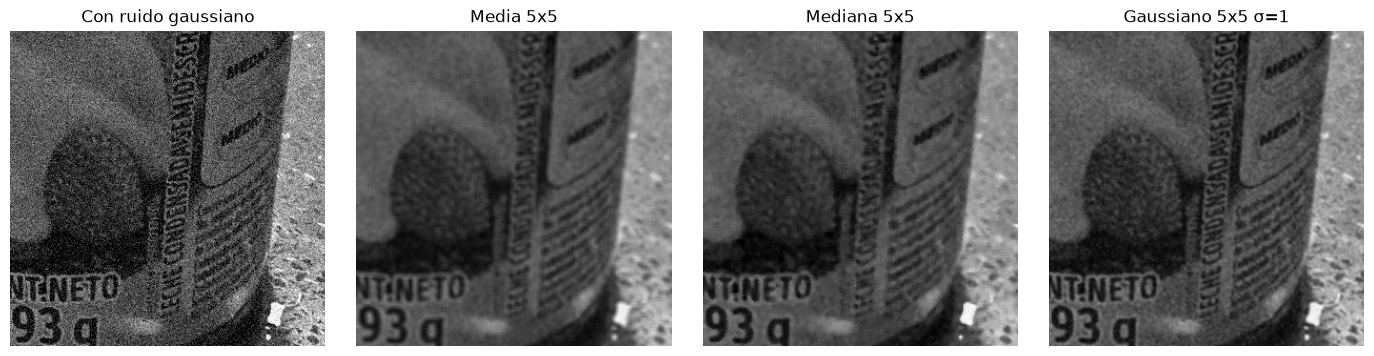

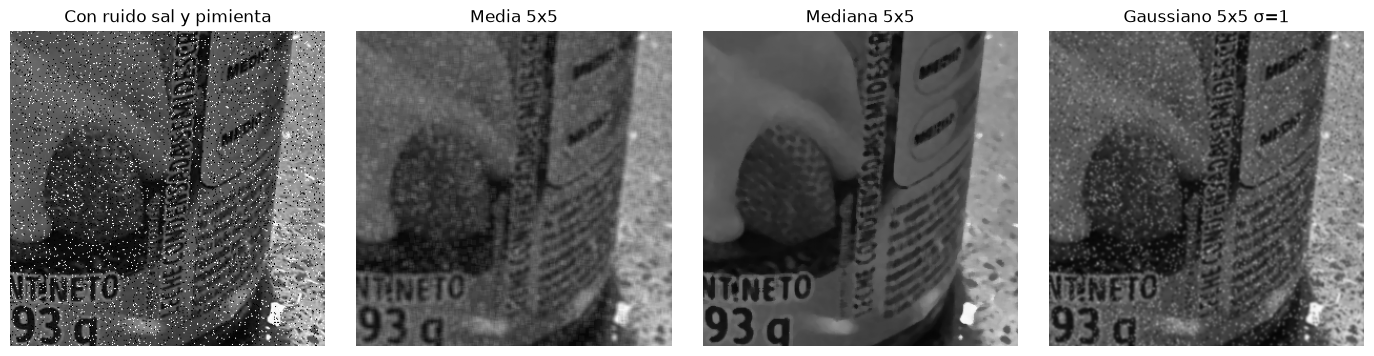

Evaluación cuantitativa: PSNR en dB (mayor valor = mejor reconstrucción):


,sin filtrar,Media 5x5,Mediana 5x5,Gaussiano 5x5 σ=1
ruido,,,,
Gaussiano (σ=25),20.3,24.0,24.3,26.4
Sal y pimienta (8 %),16.3,23.1,25.2,24.1


In [13]:
limpia = gris.copy()
rng = np.random.default_rng(0)

# 1. Ruido Gaussiano (simula ruido de sensor con poca luz o alta ganancia ISO)
ruido_gauss = np.clip(limpia + rng.normal(0, 25, limpia.shape), 0, 255).astype(np.uint8)

# 2. Ruido Sal y Pimienta (simula errores de transmisión o píxeles defectuosos)
ruido_sp = limpia.copy()
mascara = rng.random(limpia.shape)
ruido_sp[mascara < 0.04] = 0      # pimienta: 4 % de píxeles negros
ruido_sp[mascara > 0.96] = 255    # sal: 4 % de píxeles blancos

filtros = {
    "Media 5x5": lambda im: cv2.blur(im, (5, 5)),
    "Mediana 5x5": lambda im: cv2.medianBlur(im, 5),
    "Gaussiano 5x5 σ=1": lambda im: cv2.GaussianBlur(im, (5, 5), 1.0),
}

# Tabla comparativa de métricas PSNR
tabla = []
for nombre_ruido, ruidosa in [("Gaussiano (σ=25)", ruido_gauss), ("Sal y pimienta (8 %)", ruido_sp)]:
    fila = {"ruido": nombre_ruido, "sin filtrar": cv2.PSNR(limpia, ruidosa)}
    for nombre, f in filtros.items():
        fila[nombre] = cv2.PSNR(limpia, f(ruidosa))
    tabla.append(fila)

# Visualización comparativa con zoom sobre una región de interés del producto
zoom = (slice(450, 750), slice(650, 950))
for ruidosa, nombre_ruido in [(ruido_gauss, "ruido gaussiano"), (ruido_sp, "ruido sal y pimienta")]:
    mostrar([ruidosa[zoom]] + [f(ruidosa)[zoom] for f in filtros.values()],
            [f"Con {nombre_ruido}"] + list(filtros), ancho=3.5)

print("Evaluación cuantitativa: PSNR en dB (mayor valor = mejor reconstrucción):")
df_psnr = pd.DataFrame(tabla).set_index("ruido").round(1)
df_psnr


> **Observación.**
> - **Frente a ruido sal y pimienta:** El **filtro de mediana** ofrece un rendimiento superior (superando a la media y al Gaussiano). Esto ocurre porque los píxeles aislados en blanco o negro son *outliers* extremos; la mediana los descarta naturalmente al tomar el valor central, mientras que los filtros lineales (media y Gaussiano) difuminan esos valores extremos en manchas grises.
> - **Frente a ruido gaussiano:** El **filtro Gaussiano** alcanza el mejor PSNR, ya que pondera exponencialmente a los vecinos más cercanos, preservando mejor la definición de los contornos y etiquetas del producto que el filtro de media simple.
> - **Conclusión técnica:** No existe un único filtro óptimo para todos los escenarios; la elección del filtro debe basarse en la naturaleza del ruido presente en la imagen.
